# Step 1 — 1D Linear Convection

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step01_linear_convection_1d.ipynb)

*The "12 steps to Navier-Stokes" with sesmax (after Lorena Barba's CFD Python), moved from somax's tutorial series.*

The linear convection equation is the simplest PDE in computational fluid dynamics. It describes how a disturbance propagates through a medium at a constant speed without changing shape (in the continuous limit). Mastering this equation gives you the foundation for every subsequent step.

**What you'll learn:**

1. The physics of linear wave propagation and the CFL condition
2. How to set up a 1D PDE model in sesmax
3. How to compare numerical output against the analytical solution
4. How to differentiate through the simulation with `eqx.filter_grad`

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial u}{\partial t} + c \frac{\partial u}{\partial x} = 0
$$

where $c$ is the constant wave speed. The exact solution for an initial condition $u(x, 0) = u_0(x)$ is simply:

$$
u(x, t) = u_0(x - ct)
$$

The initial profile translates to the right at speed $c$ without distortion. This is pure **advection** — no diffusion, no steepening.

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ is the spatial coordinate (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$ | spatial coordinate | $\mathbb{R}$ |
| $t \in [t_0, t_1]$ | time | $\mathbb{R}$ |
| $u(x, t)$ | the advected field | $\mathbb{R}$ |
| $u_0(x)$ | initial condition, a Gaussian bump with centre $\mu_0$ and width $\sigma_0$ | $\mathbb{R}$ |
| $c$ | wave speed, the model's differentiable parameter | $\mathbb{R}$ |
| $L_x$ | domain length | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x}$ | number of interior grid cells | count |
| $\Delta x = L_x / N_{\Omega_x}$, $\Delta t$ | grid spacing and time step | $\mathbb{R}_{>0}$ |
| $u_n$ | the field in cell $n$; the vector of all cells, with ghosts, has length $N_{\Omega_x} + 2$ | $\mathbb{R}$ |
| $\nu_\text{CFL}$ | Courant number | $\mathbb{R}_{\ge 0}$ |
| $E(t)$ | energy | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |
| $N_{\mathcal{E}}$, $u_0^{(e)}$ | ensemble size and the initial condition of member $e$ | count, $\mathbb{R}$ |

### The CFL condition

The Courant-Friedrichs-Lewy (CFL) number $\nu_\text{CFL} = c \Delta t / \Delta x$ must satisfy $\nu_\text{CFL} \le 1$ for explicit upwind schemes. If the numerical domain of dependence does not contain the physical domain of dependence, the scheme is unstable.

## Grid layout and boundary conditions

sesmax uses the **Arakawa C-grid** from finitevolX. In 1D, scalar fields (like $u$) live at **T-points** (cell centres) and fluxes are computed at **U-points** (cell edges). The array holds one ghost cell at each end around the $N_{\Omega_x}$ interior cells:

| Array index | `0` | `1` … `N` | `N + 1` (or `-1`) |
| --- | --- | --- | --- |
| Role | left ghost | interior T-points, where `u` is stored and updated | right ghost |

The U-points sit between neighbouring T-points, a distance $\Delta x$ apart, and that is where `Difference1D` computes derivatives. The ghost cells are filled by the boundary conditions before each evaluation of the right-hand side.

**Periodic BCs** copy the last interior value into the opposite ghost cell, $u_0 = u_{N_{\Omega_x}}$ and $u_{N_{\Omega_x} + 1} = u_1$, so waves that exit one side re-enter from the other.

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

`LinearConvection1D.create()` builds a model on a 1D Arakawa C-grid with `nx` interior cells spanning a domain of length `Lx`. The wave speed `c` is a differentiable parameter visible to `jax.grad`.

In [4]:
# Shapes: N_Ωx = 200 interior cells

num_cells = 200
domain_length = 4.0
wave_speed = 1.0

# today (sesmax_core)
model = sxt.LinearConvection1D.create(nx=num_cells, Lx=domain_length, c=wave_speed)

print(f"Grid: Nx={model.grid.Nx} (includes 2 ghost cells), dx={model.grid.dx:.4f}")
print(f"Wave speed c = {float(model.params.c):.1f}")

Grid: Nx=202 (includes 2 ghost cells), dx=0.0200
Wave speed c = 1.0


## 2. Initial condition

We use a Gaussian bump centred at $\mu_0 = 1$ with width $\sigma_0 = 0.2$:

$$
u_0(x) = \exp\left(-\frac{(x - \mu_0)^2}{2 \sigma_0^2}\right)
$$

The state array holds $N_{\Omega_x} + 2$ values, including the two ghost cells that enforce the periodic boundary conditions.

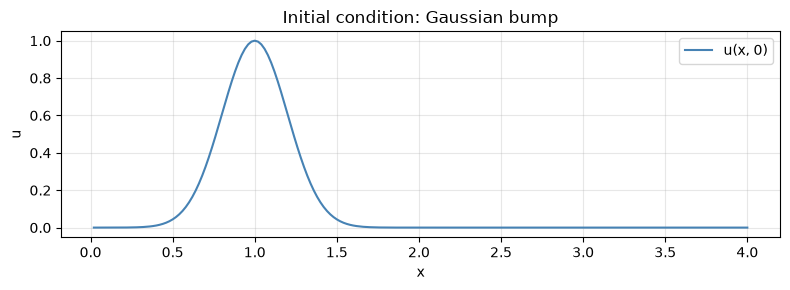

In [5]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

interior = slice(1, -1)
bump_centre = 1.0
bump_width = 0.2

# xₙ = n Δx
position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx + 2,)
# zₙ = (xₙ − μ₀) / σ₀
standardised = (position - bump_centre) / bump_width  # → (N_Ωx + 2,)
# u₀(x) = exp(−z² / 2)
initial_u = jnp.exp(-0.5 * standardised**2)  # → (N_Ωx + 2,)

# today (sesmax_core)
initial_state = sxt.LinearConvection1DState(u=initial_u)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(
    position[interior],
    initial_u[interior],
    color="steelblue",
    lw=1.5,
    label="u(x, 0)",
)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("Initial condition: Gaussian bump")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Forward simulation

We integrate from $t_0 = 0$ to $t_1 = 0.5$ using `model.integrate()`. The method wraps `diffrax.diffeqsolve` and applies the periodic boundary conditions at every evaluation of the right-hand side.

In [6]:
# Shapes: N_T = 6 saved snapshots; N_Ωx + 2 = 202 cells with the ghosts

start_time = 0.0
end_time = 0.5
time_step = 0.002

# tₖ = t₀ + k (t₁ − t₀) / (N_T − 1)
save_times = jnp.linspace(start_time, end_time, 6)  # → (N_T,)

# today (sesmax_core, diffrax)
# u(x, tₖ) for each saved time
solution = model.integrate(  # u → (N_T, N_Ωx + 2)
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

# ν_CFL = c Δt / Δx
courant_number = wave_speed * time_step / model.grid.dx  # → ()

print(f"Trajectory shape: u={solution.ys.u.shape}")
print(f"CFL number: c * dt / dx = {courant_number:.3f}")

Trajectory shape: u=(6, 202)
CFL number: c * dt / dx = 0.100


## 4. Visualize the wave propagation

The Gaussian translates to the right at speed $c = 1$. After $t = 0.5$ it should have moved a distance $c t = 0.5$.

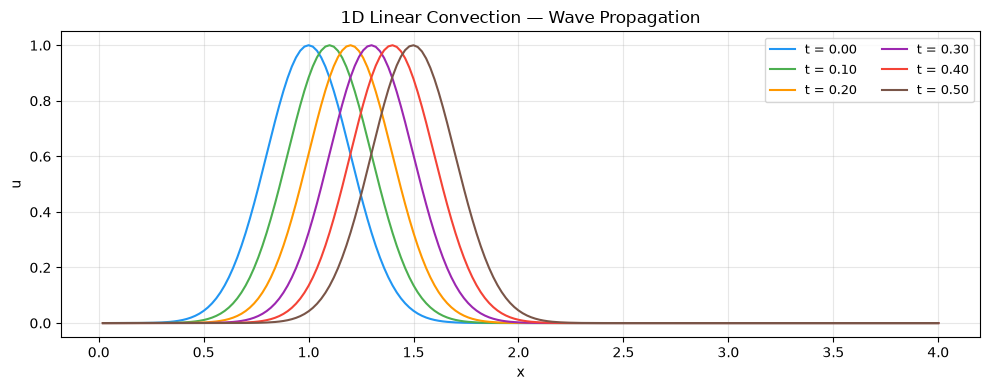

In [7]:
snapshot_colours = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0", "#F44336", "#795548"]

fig, ax = plt.subplots(figsize=(10, 4))
for snapshot, save_time in enumerate(save_times):
    ax.plot(
        position[interior],
        solution.ys.u[snapshot, interior],
        color=snapshot_colours[snapshot],
        lw=1.5,
        label=f"t = {float(save_time):.2f}",
    )
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("1D Linear Convection — Wave Propagation")
ax.legend(fontsize=9, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Comparison with the analytical solution

The exact solution is $u(x, t) = u_0(x - ct)$. With periodic BCs the shifted coordinate wraps around the domain, $x - ct \bmod L_x$. The error is measured on the interior cells by its maximum and by the discrete $L^2$ norm, $\Vert e \Vert_2 = (\Delta x \sum_n e_n^2)^{1/2}$.

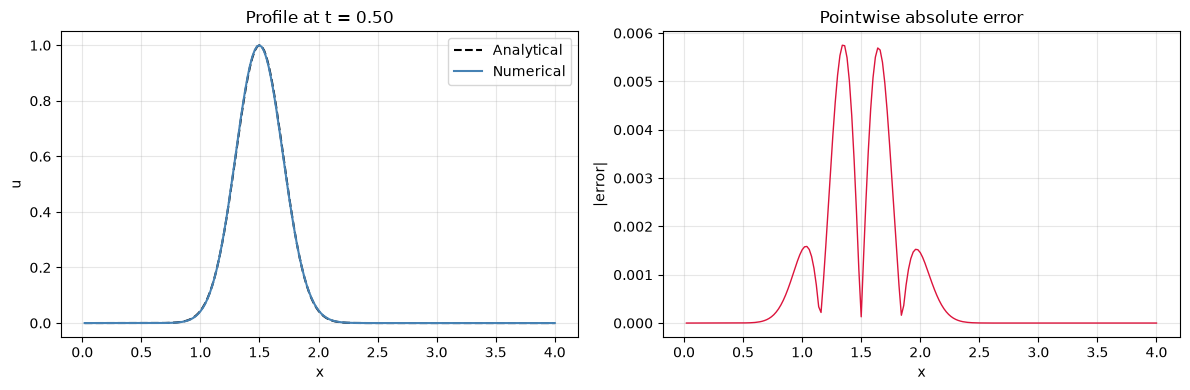

Max error: 0.005749
L2 error:  0.003391


In [8]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

# u(x, t₁)
final_u = solution.ys.u[-1]  # (N_T, N_Ωx + 2) → (N_Ωx + 2,)
# ξ = (x − c t₁) mod L_x
shifted_position = (position - wave_speed * end_time) % domain_length  # → (N_Ωx + 2,)
# zₙ = (ξₙ − μ₀) / σ₀
shifted_standardised = (shifted_position - bump_centre) / bump_width
# u(x, t₁) = u₀(ξ) = exp(−z² / 2)
exact_u = jnp.exp(-0.5 * shifted_standardised**2)  # → (N_Ωx + 2,)
# eₙ = |uₙ − uₙᵉˣᵃᶜᵗ|
error = jnp.abs(final_u - exact_u)  # → (N_Ωx + 2,)
interior_error = error[interior]  # → (N_Ωx,)
# ‖e‖_∞ = maxₙ eₙ
max_error = jnp.max(interior_error)  # → ()
# ‖e‖₂ = (Δx Σₙ eₙ²)^½
l2_error = jnp.sqrt(jnp.sum(interior_error**2) * model.grid.dx)  # → ()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- overlay ---
ax = axes[0]
ax.plot(position[interior], exact_u[interior], "k--", lw=1.5, label="Analytical")
ax.plot(
    position[interior],
    final_u[interior],
    color="steelblue",
    lw=1.5,
    label="Numerical",
)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title(f"Profile at t = {float(save_times[-1]):.2f}")
ax.legend()
ax.grid(True, alpha=0.3)

# --- error ---
ax = axes[1]
ax.plot(position[interior], interior_error, color="crimson", lw=1.0)
ax.set_xlabel("x")
ax.set_ylabel("|error|")
ax.set_title("Pointwise absolute error")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Max error: {float(max_error):.6f}")
print(f"L2 error:  {float(l2_error):.6f}")

## 6. Diagnostics — energy conservation

For the linear convection equation with periodic BCs, the total energy is conserved analytically,

$$
E(t) = \frac{1}{2} \int_0^{L_x} u(x, t)^2 \mathrm{d}x \approx \frac{\Delta x}{2} \sum_{n=1}^{N_{\Omega_x}} u_n(t)^2
$$

Numerical dissipation of the upwind scheme causes a slow decay.

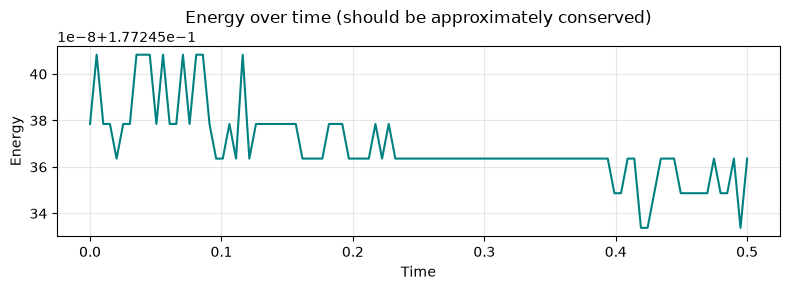

Energy: initial = 0.177245, final = 0.177245
Relative change: 0.0000%


In [9]:
# Shapes: N_T = 100 saved snapshots; N_Ωx + 2 = 202 cells with the ghosts

# tₖ, k = 0, …, N_T − 1
dense_times = jnp.linspace(start_time, end_time, 100)  # → (N_T,)

# today (sesmax_core, diffrax)
dense_solution = model.integrate(  # u → (N_T, N_Ωx + 2)
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=dense_times),
)

# today (sesmax_core)
# E(tₖ) = (Δx / 2) Σₙ uₙ(tₖ)²
diagnostics = jax.vmap(model.diagnose)(dense_solution.ys)
energy = diagnostics.energy  # → (N_T,)
# |E(t₁) − E(t₀)| / E(t₀)
relative_change = jnp.abs(energy[-1] - energy[0]) / energy[0]  # → ()

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(dense_times, energy, color="teal", lw=1.5)
ax.set_xlabel("Time")
ax.set_ylabel("Energy")
ax.set_title("Energy over time (should be approximately conserved)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Energy: initial = {float(energy[0]):.6f}, final = {float(energy[-1]):.6f}")
print(f"Relative change: {float(relative_change):.4%}")

## 7. Differentiability demo

One of the key advantages of sesmax is that every simulation is end-to-end differentiable. We define a loss that compares the final profile with a target bump centred at $x = 1.5$,

$$
\mathcal{L}(c) = \frac{1}{N_{\Omega_x}} \sum_{n=1}^{N_{\Omega_x}} \left(u_n(t_1; c) - u_n^\text{target}\right)^2
$$

and compute $\partial \mathcal{L} / \partial c$, the gradient of the loss with respect to the wave speed.

In [10]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

target_centre = 1.5

# zₙ = (xₙ − 1.5) / σ₀
target_standardised = (position - target_centre) / bump_width  # → (N_Ωx + 2,)
# uᵗᵃʳᵍᵉᵗ(x) = exp(−z² / 2)
target_u = jnp.exp(-0.5 * target_standardised**2)  # → (N_Ωx + 2,)


# today (equinox)
@eqx.filter_grad
def grad_wrt_model(model):
    """Gradient of the MSE loss ℒ(c) with respect to every float leaf of the model."""
    # today (sesmax_core, diffrax)
    # u(x, t₁; c)
    final_solution = model.integrate(initial_state, t0=0.0, t1=0.5, dt=0.002)
    predicted_u = final_solution.ys.u[-1]  # → (N_Ωx + 2,)
    # rₙ = uₙ(t₁; c) − uₙᵗᵃʳᵍᵉᵗ
    residual = predicted_u[interior] - target_u[interior]  # → (N_Ωx,)
    # ℒ(c) = (1/N_Ωx) Σₙ rₙ²
    loss = jnp.mean(residual**2)  # → ()
    return loss


# ∂ℒ/∂c
model_grads = grad_wrt_model(model)

print("--- Gradient w.r.t. model parameters ---")
print(f"  dL/d(c) = {float(model_grads.params.c):.6f}")
print()
print("The gradient tells us how to adjust the wave speed to move")
print("the final profile closer to the target location x = 1.5.")

--- Gradient w.r.t. model parameters ---
  dL/d(c) = -0.001377

The gradient tells us how to adjust the wave speed to move
the final profile closer to the target location x = 1.5.


### Joint gradient — parameters and initial state

We can compute gradients with respect to both the wave speed $c$ and the initial condition $u_0$ at once. This is the foundation for bi-level optimisation (e.g. weak-constraint 4D-Var). The loss here is the squared norm of the field at $t_1 = 0.2$, over every cell including the ghosts,

$$
\mathcal{L}(u_0, c) = \sum_{n=0}^{N_{\Omega_x} + 1} u_n(t_1; u_0, c)^2
$$

In [11]:
# Shapes: N_Ωx + 2 = 202 cells with the ghosts


def joint_loss(initial_state, model):
    # today (sesmax_core, diffrax)
    # u(x, t₁; u₀, c)
    final_solution = model.integrate(initial_state, t0=0.0, t1=0.2, dt=0.002)
    # ℒ(u₀, c) = Σₙ uₙ(t₁)²
    loss = jnp.sum(final_solution.ys.u**2)  # → ()
    return loss


def joint_loss_of_pair(pair):
    return joint_loss(*pair)


# filter_grad differentiates only the floating-point leaves: the grid's
# integer sizes are leaves too, and jax.grad would refuse them.
# today (equinox)
# (∂ℒ/∂u₀, ∂ℒ/∂c)
state_grads, model_grads = eqx.filter_grad(joint_loss_of_pair)((initial_state, model))
# maxₙ |∂ℒ/∂u₀,ₙ|
max_state_grad = jnp.max(jnp.abs(state_grads.u))  # (N_Ωx + 2,) → ()

print("--- Joint gradient ---")
print(f"  dL/d(u0) max = {float(max_state_grad):.4f}")
print(f"  dL/d(c)      = {float(model_grads.params.c):.4f}")

--- Joint gradient ---
  dL/d(u0) max = 2.0000
  dL/d(c)      = 0.0000


### Comparing adjoint methods

diffrax provides several adjoint methods for differentiating through ODE solves. Over $N_{\mathcal{T}_x}$ solver steps, `RecursiveCheckpointAdjoint` (the default) gives exact gradients with $O(\sqrt{N_{\mathcal{T}_x}})$ memory. `DirectAdjoint` stores the full trajectory ($O(N_{\mathcal{T}_x})$ memory) but can be faster for short integrations.

In [12]:
import time


def timed_grad(adjoint, label):
    # today (equinox)
    @eqx.filter_grad
    def loss_grad(model):
        # today (sesmax_core, diffrax)
        final_solution = model.integrate(
            initial_state, t0=0.0, t1=0.2, dt=0.002, adjoint=adjoint
        )
        # ℒ(c) = Σₙ uₙ(t₁; c)²
        loss = jnp.sum(final_solution.ys.u**2)  # → ()
        return loss

    # the first call compiles; time the second
    grads = loss_grad(model)
    jax.block_until_ready(grads.params.c)
    start = time.perf_counter()
    grads = loss_grad(model)
    jax.block_until_ready(grads.params.c)
    elapsed = time.perf_counter() - start
    print(f"  {label:35s}  dL/d(c)={float(grads.params.c):.4f}  ({elapsed:.4f}s)")


print("--- Adjoint method comparison ---")
# today (diffrax)
timed_grad(dfx.RecursiveCheckpointAdjoint(), "RecursiveCheckpoint")
# today (diffrax)
timed_grad(dfx.DirectAdjoint(), "Direct")

--- Adjoint method comparison ---


  RecursiveCheckpoint                  dL/d(c)=0.0000  (3.8405s)


  Direct                               dL/d(c)=-0.0000  (5.4987s)


### Ensemble simulation with `eqx.filter_vmap`

We can run an ensemble of $N_{\mathcal{E}} = 10$ simulations from perturbed initial conditions to explore sensitivity, $u_0^{(e)} = u_0 + \delta^{(e)}$ with $\delta_n^{(e)} \sim \mathcal{N}(0, 0.01^2)$, in one vectorised call.

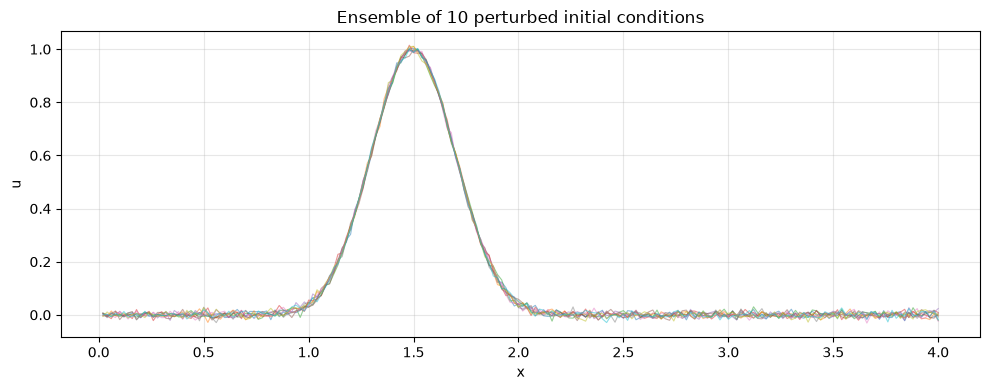

In [13]:
# Shapes: N_E = 10 members; N_Ωx + 2 = 202 cells with the ghosts

import jax.random as jrandom


num_members = 10
perturbation_scale = 0.01
key = jrandom.PRNGKey(42)

# δₙ⁽ᵉ⁾ ~ 𝒩(0, 0.01²)
noise = jrandom.normal(key, shape=(num_members, model.grid.Nx))  # → (N_E, N_Ωx + 2)
perturbations = perturbation_scale * noise  # → (N_E, N_Ωx + 2)
# u₀⁽ᵉ⁾ = u₀ + δ⁽ᵉ⁾
ensemble_initial_u = einx.add(  # (N_Ωx + 2,) → (N_E, N_Ωx + 2)
    "cell, member cell -> member cell", initial_state.u, perturbations
)


def integrate_member(member_initial_u):
    # today (sesmax_core)
    member_state = sxt.LinearConvection1DState(u=member_initial_u)
    # today (sesmax_core, diffrax)
    # u⁽ᵉ⁾(x, t₁)
    member_solution = model.integrate(
        member_state,
        t0=0.0,
        t1=0.5,
        dt=0.002,
        saveat=dfx.SaveAt(t1=True),
    )
    return member_solution


# today (equinox)
ensemble_solution = eqx.filter_vmap(integrate_member)(  # u → (N_E, 1, N_Ωx + 2)
    ensemble_initial_u
)

fig, ax = plt.subplots(figsize=(10, 4))
for member in range(num_members):
    ax.plot(
        position[interior],
        ensemble_solution.ys.u[member, -1, interior],
        lw=0.8,
        alpha=0.5,
    )
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title(f"Ensemble of {num_members} perturbed initial conditions")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary

| Concept | sesmax API |
|---------|-----------|
| Create model | `LinearConvection1D.create(nx=200, Lx=4.0, c=1.0)` |
| Initial state | `LinearConvection1DState(u=...)` |
| Forward sim | `model.integrate(state0, t0, t1, dt, saveat=...)` |
| Diagnostics | `model.diagnose(state)` |
| Grad w.r.t. params | `eqx.filter_grad(loss)(model)` |

**Key takeaway:** Linear convection translates a signal without distortion. The CFL condition $c \Delta t / \Delta x \le 1$ governs stability.

**Next:** [Step 2 — Nonlinear Convection](step02_nonlinear_convection_1d.ipynb) introduces amplitude-dependent wave speed and shock formation.